In [1]:
import numpy as np
import pandas as pd
import lseg.data as ld
import matplotlib.pyplot as plt

from hurst import compute_Hc
from statsmodels.graphics.tsaplots import plot_acf


In [2]:
ld.open_session()

df = ld.get_history("AAPL.O",
                    fields=["TRDPRC_1"],
                    interval="5min",
                    start="2025-01-01",
                    end="2026-01-01")
print(df.head())
print(df.shape)
print(df.dtypes)

c:\Users\fazru\AppData\Local\Programs\Python\Python314\Lib\site-packages\lseg\data\_access_layer\session.py:72:FutureWarning: 
You open a platform session using the default value of the signon_control parameter (signon_control=True).
In future library version v2.0, this default will be changed to False.
If you want to keep the same behavior as today, you will need to set the signon_control parameter to True either in the library configuration file
({'sessions':{'platform':{'your_session_name':{'signon_control':true}}}}) or in your code where you create the Platform Session.
These alternative options are already supported in the current version of the library.
Exception in thread AuthManager-Thread:
Traceback (most recent call last):
  File "c:\Users\fazru\AppData\Local\Programs\Python\Python314\Lib\threading.py", line 1082, in _bootstrap_inner
    self._context.run(self.run)
    ~~~~~~~~~~~~~~~~~^^^^^^^^^^
  File "c:\Users\fazru\AppData\Local\Programs\Python\Python314\Lib\threading.py"

ValueError: Session is not opened. Can't send any request

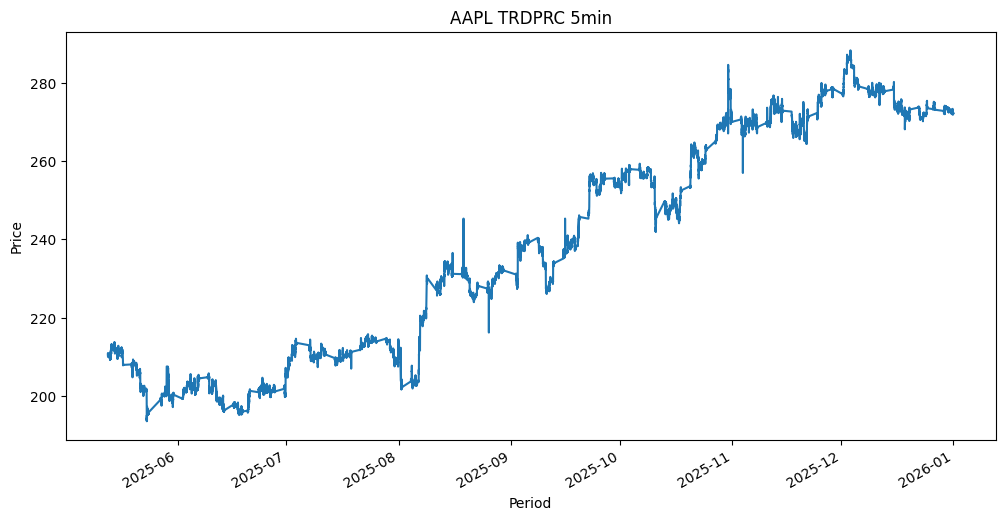

In [3]:
df["TRDPRC_1"].plot(figsize=(12,6), title="AAPL TRDPRC 5min")
plt.ylabel("Price")
plt.xlabel("Period")
plt.show()

## ACF - AutoCorrelation Function

ACF - How similar is the current value to its own past values

    Lag 0  →  compare data[now] with data[now] = always 1.0
    Lag 1  →  compare data[now] with data[+1]
    Lag 2  →  compare data[now] with data[+2]
    Lag 3  →  compare data[now] with data[+3] as so on so forth

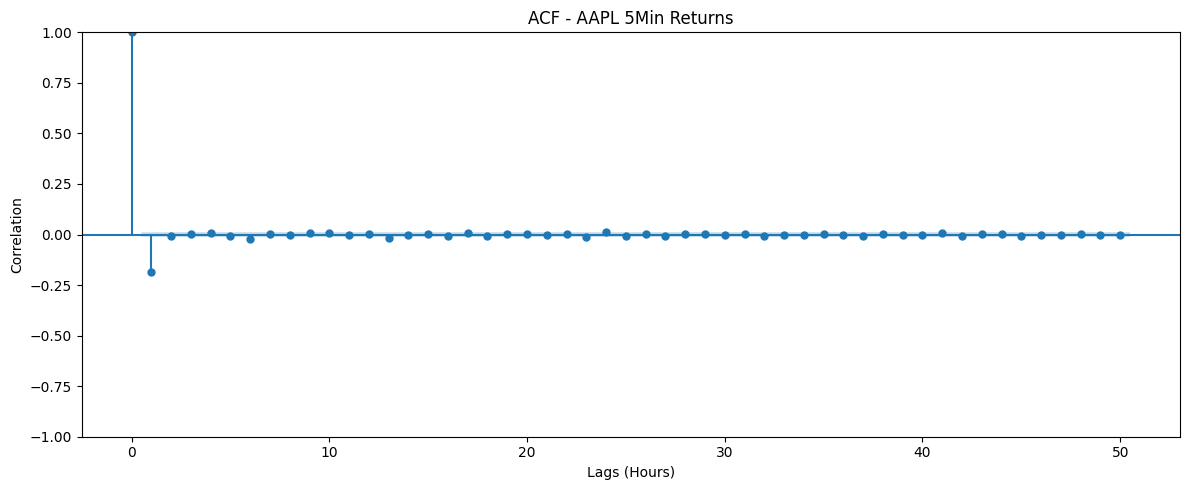

In [6]:
df["RETURNS"] = np.log(df["TRDPRC_1"] / df["TRDPRC_1"].shift(1))

fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(df['RETURNS'].dropna(), lags=50, ax=ax)
ax.set_title('ACF - AAPL 5Min Returns')
ax.set_xlabel('Lags (Hours)')
ax.set_ylabel('Correlation')
plt.tight_layout()
plt.show()

In [7]:
H, c, data = compute_Hc(df["TRDPRC_1"], kind="price", simplified=True)

if H < 0.5:
    print(f"Mean Reverting (H = {H:.2f} < 0.5)")
elif H > 0.5:
    print(f"Trending (H = {H:.2F} > 0.5)")   
else:
    print(f"Random Walk (H = {H:.2f})")     

Trending (H = 0.54 > 0.5)
